# **TUGAS 1 PENGANTAR DATA MINING**

Nama  : Cheisa Billy Putra Antoni

NIM   : 25/566096/PA/23888

Kelas : B

# **Nomor 2: Market Basket Analysis**

Siang itu kedai sudah agak sepi. Jam makan siang baru lewat, dan sisa antrean tinggal sepasang kekasih yang sedang menunggu bungkusan. Si peneliti duduk di pojok seperti biasa, menghabiskan sop ayamnya dan tak sengaja melihat pasangan tersebut yang mana memicu kata yang sedang marak yakni "when yh.." terucap lirih dari mulutnya.

Dari dapur terdengar suara Bu Jahro yang cukup keras. Bukan marah yang membentak, tapi marah yang ditahan-tahan, jenis yang justru lebih bikin ciut. Pak Suryo baru pulang dari pasar pagi itu, dan belanjaannya ternyata tidak sesuai daftar. Bawang putih yang dibeli kebanyakan, seledri lupa, dan ia malah membawa pulang sekantong besar tepung yang tidak ada di catatan.

Tak lama Pak Suryo keluar dari dapur dengan wajah kusut. Ia mengelap meja yang sebenarnya sudah bersih, lalu duduk di kursi seberang si peneliti tanpa diminta.

"Aku ben dino wes blanja, nanging yo esih salah" keluhnya dalam bahasa jawa.

Si peneliti menaruh sendoknya. Ia sebenarnya sudah lama memperhatikan hal itu. Selama menjadi pelanggan tetap makan di sini, ia sering melihat orang yang memesan sop hampir selalu menambah kerupuk, dan yang memesan teh manis biasanya ikut mengambil gorengan. Kebiasaan itu terjadi berulang-ulang, hanya tidak pernah ada yang mencatatnya.

"Sebenarnya ada polanya lho Pak," kata si peneliti. "Ada metode namanya market basket analysis. Dari data transaksi, kita bisa lihat barang apa saja yang sering dibeli bersamaan, terus dihitung seberapa kuat hubungannya. Jadi belanja stok bisa berdasarkan itu, bukan cuma feeling."

Pak Suryo mengerutkan dahi. Istilahnya terdengar asing, tapi ia menangkap satu hal, yakni ada cara untuk tidak lagi salah belanja. Ia bertanya bagaimana caranya, dan si peneliti menjelaskan singkat bahwa ada dua algoritma yang biasa dipakai, Apriori dan FP-Growth. Keduanya sama-sama mencari kombinasi barang yang sering muncul, hanya cara kerjanya berbeda.

"ra ono datane toh, iki mung kedai sop sanes restoran"

Si peneliti mengaku itu memang kendalanya. Tapi ia punya dataset transaksi Instacart, platform belanja bahan makanan dengan jutaan keranjang belanja, yang kebetulan sedang ia pakai untuk latihan praktikum. Kalau polanya bisa ditemukan di sana, hasilnya bisa dijadikan gambaran untuk menata stok kedai.

Pak Suryo diam sebentar, lalu menoleh ke arah dapur. Bu Jahro masih sibuk memilah belanjaan yang salah tadi dengan muka tertekuk.

"Ya wes,tulung sampeyan atur mawon, ben aku ra dinesuhi terus." ucap Pak Suryo sambil melirikkan mata ke Bu Jahro.

Si peneliti tertawa kecil, lalu segera membuka laptopnya. Ia menulis di halaman baru catatannya yakni cari barang yang selalu dibeli bersamaan, lalu tentukan mana yang benar-benar penting.

Anda sebagai peneliti kini diminta mengerjakan analisis tersebut. Gunakan dataset transaksi Instacart, terapkan algoritma *Apriori* dan *FP-Growth* untuk menemukan frequent itemsets dan membentuk association rules, lalu berikan wawasan yang dapat membantu Kedai Sop Ayam 272 dengan menggunakan dataset simulasi transaksi Instacart.

Dataset : [Instacart](https://drive.google.com/drive/folders/1K9rxtyaD36Ko1kjTJc60yh5CFiNsTFyX?usp=sharing)

**Catatan**:

*   Seluruh pertanyaan dalam analisis ini harus dijawab secara komprehensif.

*   Berikan penjelasan yang jelas dan sistematis untuk setiap tahapan analisis, mulai dari penyiapan data hingga interpretasi akhir.

*   Agar interpretasi lebih mudah, gunakan nama produk yang disederhanakan berdasarkan *dataset* kategori (*aisles*) alih-alih nama aslinya.

*   Terapkan ambang batas *support* minimum sebesar 0,08 dan ambang batas *confidence* minimum sebesar 0,55 di sepanjang proses analisis.

# **Jawab:**

# 1. Import Libraries & Datasets

In [48]:
# Import Libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import mlxtend as ml

from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth

In [49]:
# Configuration
pd.set_option('display.max_columns', None)
sns.set_context('notebook')
sns.set_style('whitegrid')
sns.set_palette('tab10')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11

In [50]:
# Import Dataset
path = '../data/'
departments = pd.read_csv(path + 'departments.csv')
orders = pd.read_csv(path + 'orders.csv')
products = pd.read_csv(path + 'products.csv')
aisles = pd.read_csv(path + 'aisles.csv')

In [51]:
# Merge Datasets
df_merged = orders.merge(products, on='product_id', how='left') \
                  .merge(aisles, on='aisle_id', how='left') \
                  .merge(departments, on='department_id', how='left')

display(df_merged.head())
print("\nTotal Baris Item Transaksi:", df_merged.shape[0])
print("Jumlah Transaksi Unik (Order ID):", df_merged['order_id'].nunique())
print("Jumlah Produk Unik:", df_merged['product_id'].nunique())

,order_id,product_id,add_to_cart_order,reordered,product_name,aisle_id,department_id,aisle,department
0,1,49302,1,1,Bulgarian Yogurt,120,16,yogurt,dairy eggs
1,1,11109,2,1,Organic 4% Milk Fat Whole Milk Cottage Cheese,108,16,other creams cheeses,dairy eggs
2,1,10246,3,0,Organic Celery Hearts,83,4,fresh vegetables,produce
3,1,49683,4,0,Cucumber Kirby,83,4,fresh vegetables,produce
4,1,43633,5,1,Lightly Smoked Sardines in Olive Oil,95,15,canned meat seafood,canned goods



Total Baris Item Transaksi: 1384617
Jumlah Transaksi Unik (Order ID): 131209
Jumlah Produk Unik: 39123


**Interpretasi:**
- Import semua data awal, kemudian lakukan merge pada data orders terhadap data product, aisles, dan departments.
- Setelah proses merge, diperoleh total baris item transaksi sebanyak 1.384.617 baris dengan jumlah transaksi unik sebesar 131.209 baris dan jumlah produk unik sebanyak 39.123 baris.

# 2. Data Profiling

In [52]:
# Hitung 10 Produk Teratas
top_products = df_merged['product_name'].value_counts().head(10)
print("\nTop 10 Produk Paling Sering Dibeli")
print(top_products)


Top 10 Produk Paling Sering Dibeli
product_name
Banana                    18726
Bag of Organic Bananas    15480
Organic Strawberries      10894
Organic Baby Spinach       9784
Large Lemon                8135
Organic Avocado            7409
Organic Hass Avocado       7293
Strawberries               6494
Limes                      6033
Organic Raspberries        5546
Name: count, dtype: int64


**Interpretasi:**
- Produk pisang menempati dua posisi teratas secara keseluruhan, yaitu Banana reguler sebanyak 18.726 pembelian dan Bag of Organic Bananas sebanyak 15.480 pembelian.
- Mayoritas dari 10 produk teratas merupakan produk berbahan organik (6 dari 10 produk), seperti Organic Strawberries (10.894) dan Organic Baby Spinach (9.784).
- Seluruh produk yang masuk dalam daftar 10 besar didominasi oleh kategori bahan segar (fresh produce), khususnya buah-buahan dan sayuran hijau.
- Buah jenis buni/stroberi (Strawberries, Organic Raspberries) serta buah sitrus (Large Lemon, Limes) menjadi favorit pelanggan dengan angka pembelian masing-masing di atas 5.000 kali.
- Kategori alpukat memiliki pangsa pembelian yang kuat melalui dua varian (Organic Avocado sebanyak 7.409 dan Organic Hass Avocado sebanyak 7.293).

In [53]:
# Hitung 10 Aisle Teratas
top_aisles = df_merged['aisle'].value_counts().head(10)
print("\nTop 10 Aisle Paling Sering Dibeli")
print(top_aisles)


Top 10 Aisle Paling Sering Dibeli
aisle
fresh vegetables                 150609
fresh fruits                     150473
packaged vegetables fruits        78493
yogurt                            55240
packaged cheese                   41699
water seltzer sparkling water     36617
milk                              32644
chips pretzels                    31269
soy lactosefree                   26240
bread                             23635
Name: count, dtype: int64


**Interpretasi:**
- Kategori fresh vegetables (150.609) dan fresh fruits (150.473) memimpin secara signifikan di posisi teratas dengan jumlah pembelian yang hampir seimbang dan melebihi 150 ribu kali.
- Kategori packaged vegetables fruits berada di posisi ketiga dengan 78.493 kali pembelian, menunjukkan tingginya minat pelanggan terhadap opsi sayur dan buah siap saji/kemasan.
- Produk olahan susu memiliki porsi yang sangat kuat dengan masuknya yogurt (55.240), packaged cheese (41.699), serta milk (32.644) ke dalam daftar 10 besar.
- Kategori minuman seperti water seltzer sparkling water (36.617) dan camilan chips pretzels (31.269) menjadi pilihan utama pelanggan untuk kebutuhan konsumsi sehari-hari.
- Kategori soy lactosefree (26.240) dan bread (23.635) melengkapi posisi 10 teratas, mencerminkan preferensi pelanggan terhadap produk alternatif nabati serta bahan pokok harian.

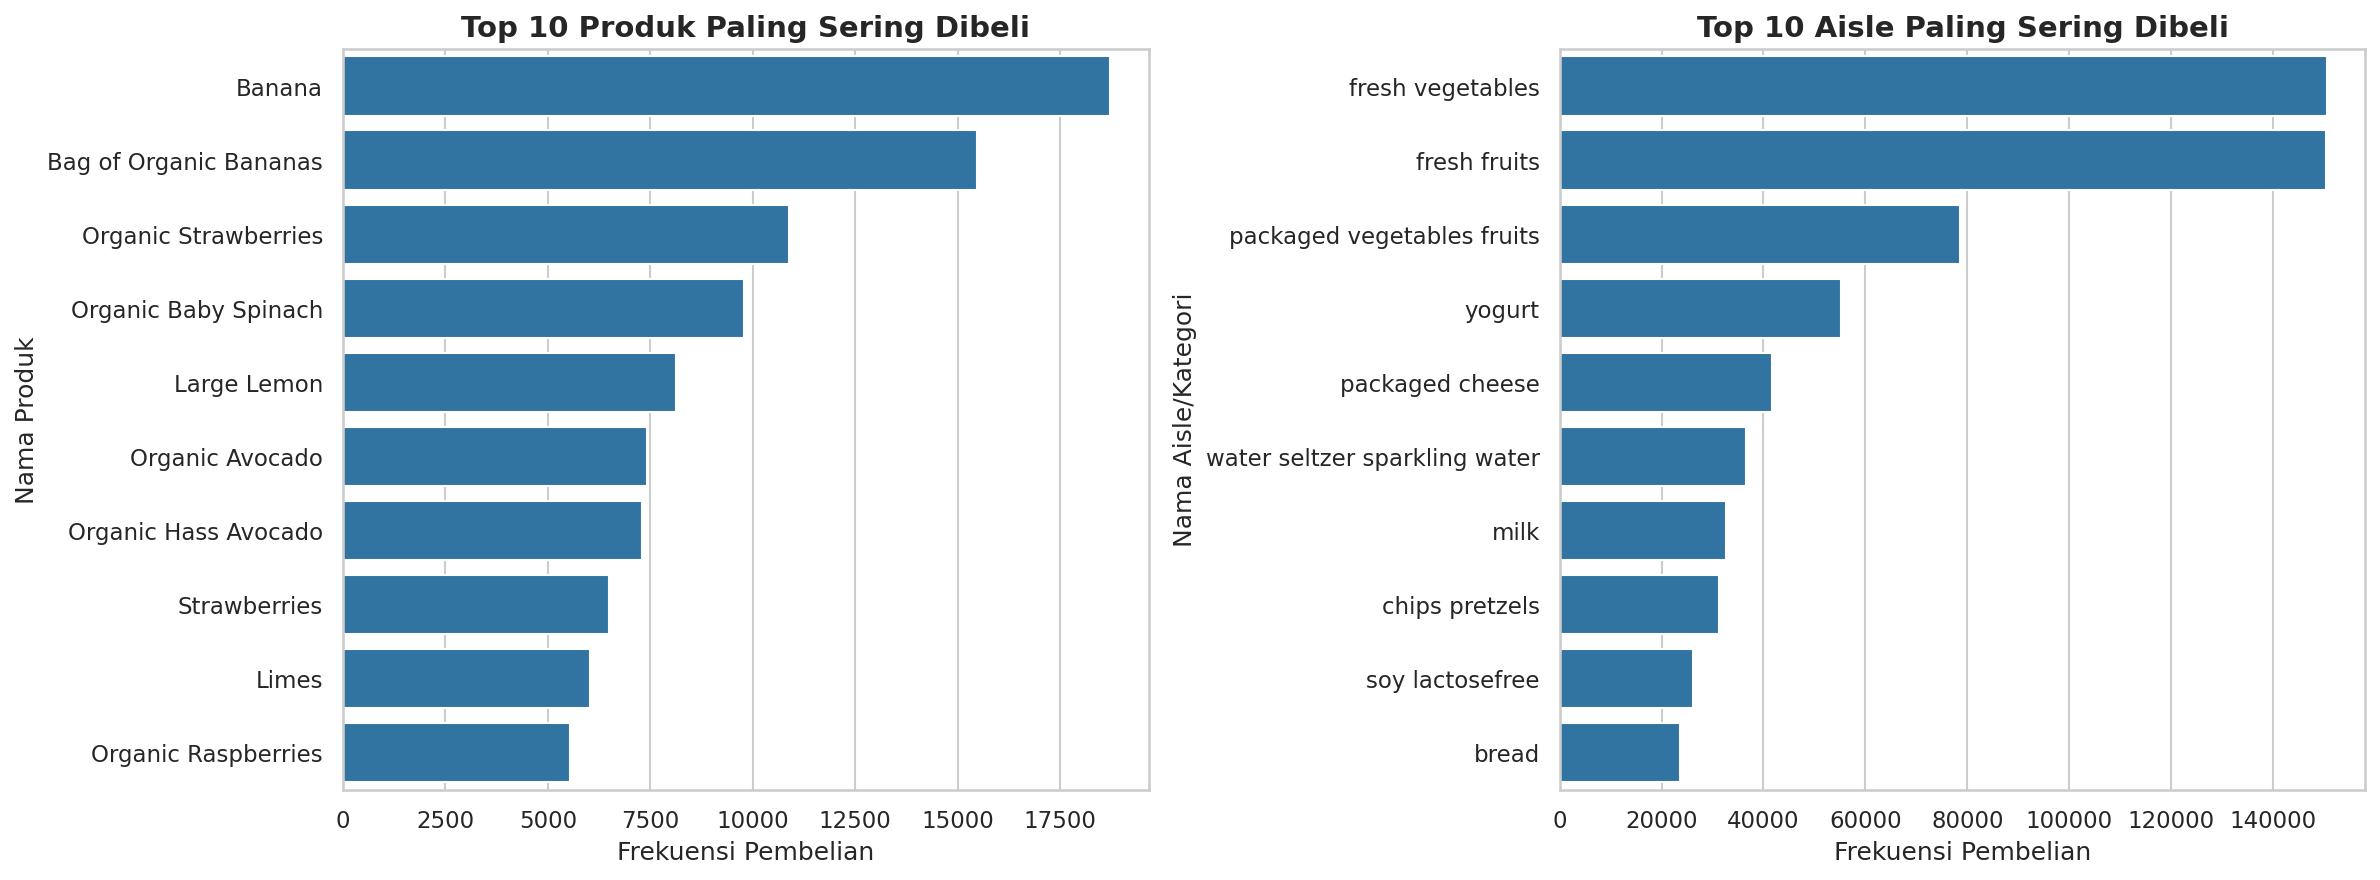

In [54]:
# Visualisasi Data Top 10 Produk & Top 10 Aisle
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=top_products.values, y=top_products.index, ax=axes[0])
axes[0].set_title('Top 10 Produk Paling Sering Dibeli', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Frekuensi Pembelian', fontsize=12)
axes[0].set_ylabel('Nama Produk', fontsize=12)

sns.barplot(x=top_aisles.values, y=top_aisles.index, ax=axes[1])
axes[1].set_title('Top 10 Aisle Paling Sering Dibeli', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Frekuensi Pembelian', fontsize=12)
axes[1].set_ylabel('Nama Aisle/Kategori', fontsize=12)

plt.tight_layout()
plt.show()

**Interpretasi Visualisasi Data Top 10 Produk & Top 10 Aisle:**
- Pada grafik sebelah kiri, produk individu yang paling banyak dibeli didominasi oleh buah dan sayuran segar, di mana Banana dan Bag of Organic Bananas menjadi produk teratas dengan frekuensi tertinggi melebihi 15.000 pembelian.
- Sebagian besar item spesifik yang masuk dalam 10 besar merupakan varian organik (Organic Strawberries, Organic Baby Spinach, Organic Avocado, Organic Hass Avocado, dan Organic Raspberries), menunjukkan preferensi pelanggan yang kuat terhadap produk alami.
- Pada grafik sebelah kanan, kategori (aisle) fresh vegetables dan fresh fruits memimpin pasar secara signifikan dengan volume frekuensi jauh melebihi 140.000 transaksi.

# 3. Transformasi

In [55]:
# Membuat DataFrame Pivot Dengan Menggabungkan Orders & Aisles
df = orders.merge(products, on='product_id', how='left') \
           .merge(aisles, on='aisle_id', how='left')
df['QUANTITY'] = 1
dfHotEncoded = df.pivot_table(
    index='order_id', 
    columns='aisle', 
    values='QUANTITY'
).fillna(0)
dfHotEncoded.head()

aisle,air fresheners candles,asian foods,baby accessories,baby bath body care,baby food formula,bakery desserts,baking ingredients,baking supplies decor,beauty,beers coolers,body lotions soap,bread,breakfast bakery,breakfast bars pastries,bulk dried fruits vegetables,bulk grains rice dried goods,buns rolls,butter,candy chocolate,canned fruit applesauce,canned jarred vegetables,canned meals beans,canned meat seafood,cat food care,cereal,chips pretzels,cleaning products,cocoa drink mixes,coffee,cold flu allergy,condiments,cookies cakes,crackers,cream,deodorants,diapers wipes,digestion,dish detergents,dog food care,doughs gelatins bake mixes,dry pasta,eggs,energy granola bars,energy sports drinks,eye ear care,facial care,feminine care,first aid,food storage,fresh dips tapenades,fresh fruits,fresh herbs,fresh pasta,fresh vegetables,frozen appetizers sides,frozen breads doughs,frozen breakfast,frozen dessert,frozen juice,frozen meals,frozen meat seafood,frozen pizza,frozen produce,frozen vegan vegetarian,fruit vegetable snacks,grains rice dried goods,granola,hair care,honeys syrups nectars,hot cereal pancake mixes,hot dogs bacon sausage,ice cream ice,ice cream toppings,indian foods,instant foods,juice nectars,kitchen supplies,kosher foods,latino foods,laundry,lunch meat,marinades meat preparation,meat counter,milk,mint gum,missing,more household,muscles joints pain relief,nuts seeds dried fruit,oils vinegars,oral hygiene,other,other creams cheeses,packaged cheese,packaged meat,packaged poultry,packaged produce,packaged seafood,packaged vegetables fruits,paper goods,pasta sauce,pickled goods olives,plates bowls cups flatware,popcorn jerky,poultry counter,prepared meals,prepared soups salads,preserved dips spreads,protein meal replacements,red wines,refrigerated,refrigerated pudding desserts,salad dressing toppings,seafood counter,shave needs,skin care,soap,soft drinks,soup broth bouillon,soy lactosefree,specialty cheeses,specialty wines champagnes,spices seasonings,spirits,spreads,tea,tofu meat alternatives,tortillas flat bread,trail mix snack mix,trash bags liners,vitamins supplements,water seltzer sparkling water,white wines,yogurt
order_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
36,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
38,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
96,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,

**Interpretasi:**
- Tabel pivot mengubah struktur data vertikal (per item transaksi) menjadi format matriks horizontal, di mana baris mewakili ID transaksi (order_id) dan kolom mewakili nama kategori (aisle).
- Nilai dalam tabel pivot menunjukkan keberadaan produk dari aisle tertentu dalam satu transaksi, di mana nilai 1.0 menandakan kategori tersebut dibeli dan 0.0 menandakan tidak dibeli.
- Penggunaan .fillna(0) berhasil menggantikan seluruh nilai kosong (NaN) menjadi 0.0 untuk mempertegas kategori yang tidak terdapat dalam transaksi.

In [56]:
# Binarisasi Menggunakan One-Hot Encoding
dfHotEncoded[dfHotEncoded > 0] = 1
display(dfHotEncoded.head())
print("\nJumlah Baris:", dfHotEncoded.shape[0])
print("Jumlah Kolom:", dfHotEncoded.shape[1])

aisle,air fresheners candles,asian foods,baby accessories,baby bath body care,baby food formula,bakery desserts,baking ingredients,baking supplies decor,beauty,beers coolers,body lotions soap,bread,breakfast bakery,breakfast bars pastries,bulk dried fruits vegetables,bulk grains rice dried goods,buns rolls,butter,candy chocolate,canned fruit applesauce,canned jarred vegetables,canned meals beans,canned meat seafood,cat food care,cereal,chips pretzels,cleaning products,cocoa drink mixes,coffee,cold flu allergy,condiments,cookies cakes,crackers,cream,deodorants,diapers wipes,digestion,dish detergents,dog food care,doughs gelatins bake mixes,dry pasta,eggs,energy granola bars,energy sports drinks,eye ear care,facial care,feminine care,first aid,food storage,fresh dips tapenades,fresh fruits,fresh herbs,fresh pasta,fresh vegetables,frozen appetizers sides,frozen breads doughs,frozen breakfast,frozen dessert,frozen juice,frozen meals,frozen meat seafood,frozen pizza,frozen produce,frozen vegan vegetarian,fruit vegetable snacks,grains rice dried goods,granola,hair care,honeys syrups nectars,hot cereal pancake mixes,hot dogs bacon sausage,ice cream ice,ice cream toppings,indian foods,instant foods,juice nectars,kitchen supplies,kosher foods,latino foods,laundry,lunch meat,marinades meat preparation,meat counter,milk,mint gum,missing,more household,muscles joints pain relief,nuts seeds dried fruit,oils vinegars,oral hygiene,other,other creams cheeses,packaged cheese,packaged meat,packaged poultry,packaged produce,packaged seafood,packaged vegetables fruits,paper goods,pasta sauce,pickled goods olives,plates bowls cups flatware,popcorn jerky,poultry counter,prepared meals,prepared soups salads,preserved dips spreads,protein meal replacements,red wines,refrigerated,refrigerated pudding desserts,salad dressing toppings,seafood counter,shave needs,skin care,soap,soft drinks,soup broth bouillon,soy lactosefree,specialty cheeses,specialty wines champagnes,spices seasonings,spirits,spreads,tea,tofu meat alternatives,tortillas flat bread,trail mix snack mix,trash bags liners,vitamins supplements,water seltzer sparkling water,white wines,yogurt
order_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
36,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
38,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
96,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,


Jumlah Baris: 131209
Jumlah Kolom: 134


**Interpretasi:**
- HotEncoder memastikan seluruh nilai kuantitas atau frekuensi pembelian di atas 0 diubah secara konsisten menjadi nilai biner mutlak 1.
- Hasil tabel pivot biner ini membedakan secara tegas antara kategori yang pernah dibeli (bernilai 1) dan kategori yang tidak ada dalam transaksi (bernilai 0).
- Tabel pivot biner ini memiliki jumlah baris sebnayak 131.209 dan jumlah kolom sebanyak 134.
- Struktur tabel pivot biner ini sudah siap digunakan sebagai input langsung untuk ekstraksi frequent itemsets menggunakan algoritma Apriori atau FP-Growth.

# 4. Association Rule Apriori

In [57]:
# Memilih Frequent Itemsets Menggunakan Algoritma Apriori
df_apriori = apriori(dfHotEncoded, min_support=0.08, use_colnames=True)
df_apriori.head()

/home/billyimpostor/.local/lib/python3.11/site-packages/mlxtend/frequent_patterns/fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,support,itemsets
0,0.163769,(bread)
1,0.097928,(cereal)
2,0.176680,(chips pretzels)
3,0.119428,(crackers)
4,0.087105,(cream)


**Interpretasi:**
- Pemanggilan fungsi apriori diatas menyaring kategori yang hanya muncul setidaknya di 8% dari total keseluruhan transaksi.
- Chips pretzels menjadi item tunggal dengan nilai support sebesar 0.176680 (muncul di sekitar 17.67% dari total transaksi).
- Kategori bread dengan nilai support 0.163769 (sekitar 16.38% transaksi), menunjukkan roti sebagai bahan makanan pokok harian yang cukup sering dibeli.
- Kategori crackers dan cereal masing-masing mencatatkan kepopuleran sebesar 11.94% (support 0.119428) dan 9.79% (support 0.097928) dari seluruh keranjang belanjaan.
- Kategori cream berhasil lolos penyaringan frequent itemset dengan nilai support 0.087105 (sekitar 8.71%), yang berarti berada sedikit di atas ambang batas minimal 8%.

In [58]:
# Memilih Rules Asosiasi Yang Kuat
df_rule_apriori = association_rules(df_apriori, metric="confidence", min_threshold=0.55).sort_values(by=['confidence'], ascending=False)
df_rule_apriori.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
43,"(packaged vegetables fruits, yogurt, fresh veg...",(fresh fruits),0.094940,0.550099,0.083173,0.876054,1.592537,1.0,0.030946,3.629800,0.411101,0.148029,0.724503,0.513625
15,(fresh herbs),(fresh vegetables),0.096868,0.450975,0.083470,0.861684,1.910712,1.0,0.039785,3.969343,0.527758,0.179747,0.748069,0.523386
37,"(packaged vegetables fruits, yogurt)",(fresh fruits),0.132834,0.550099,0.111105,0.836422,1.520492,1.0,0.038033,2.750374,0.394755,0.194298,0.636413,0.519197
31,"(yogurt, fresh vegetables)",(fresh fruits),0.146682,0.550099,0.122240,0.833368,1.514941,1.0,0.041550,2.699964,0.398337,0.212761,0.629625,0.527791
33,"(milk, packaged vegetables fruits)",(fresh fruits),0.106243,0.550099,0.087509,0.823673,1.497316,1.0,0.029065,2.551511,0.371620,0.153840,0.608075,0.491376


**Interpretasi:**
- Kode menggunakan fungsi association_rules() dengan metrik confidence minimal sebesar 0.55 dan diurutkan secara menurun untuk menampilkan aturan asosiasi terkuat.
- Aturan pada indeks 43 menunjukkan bahwa pelanggan yang membeli packaged vegetables fruits, yogurt, dan fresh vegetables memiliki kemungkinan sebesar 87.61 (confidence 0.876054) untuk juga membeli fresh fruits.
- Pembelian fresh herbs (indeks 15) sangat kuat mendorong pembelian fresh vegetables dengan nilai lift tertinggi sebesar 1.910712 dan confidence 86.17% (0.861684).
- Empat dari lima aturan teratas pada tabel menempatkan fresh fruits sebagai consequent (produk yang dibeli kemudian), menegaskan bahwa buah segar adalah produk pelengkap utama saat pelanggan membeli kombinasi produk dairy (yogurt, milk) dan sayuran.
- Seluruh aturan teratas memiliki nilai lift lebih besar dari 1.0 (berkisar antara 1.497 hingga 1.910), yang membuktikan bahwa hubungan antar produk dalam aturan tersebut bersifat positif dan bukan terjadi secara kebetulan.

In [59]:
# Mencari Petunjuk Hubungan Dua Itemset Ketika Muncul Bersamaan Dengan Lift
df_lift_apriori = association_rules(df_apriori, metric='lift', min_threshold=1).sort_values(by=['support'], ascending=False)
df_lift_apriori.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
16,(fresh vegetables),(fresh fruits),0.450975,0.550099,0.327333,0.725833,1.319458,1.0,0.079252,1.640974,0.440987,0.485843,0.390606,0.660438
17,(fresh fruits),(fresh vegetables),0.550099,0.450975,0.327333,0.595043,1.319458,1.0,0.079252,1.355760,0.538148,0.485843,0.262406,0.660438
24,(packaged vegetables fruits),(fresh fruits),0.383030,0.550099,0.287282,0.750025,1.363435,1.0,0.076577,1.799781,0.432044,0.444814,0.444377,0.636131
25,(fresh fruits),(packaged vegetables fruits),0.550099,0.383030,0.287282,0.522237,1.363435,1.0,0.076577,1.291371,0.592483,0.444814,0.225629,0.636131
43,(fresh vegetables),(packaged vegetables fruits),0.450975,0.383030,0.252361,0.559589,1.460953,1.0,0.079624,1.400896,0.574683,0.433874,0.286171,0.609221


**Interpretasi:**
- Kode menggunakan fungsi association_rules() dengan filter metric='lift' dan min_threshold=1, lalu mengurutkan hasilnya berdasarkan support secara menurun untuk menampilkan pasangan itemset yang paling sering muncul bersamaan di seluruh transaksi.
- Pasangan fresh vegetables dan fresh fruits (indeks 16 & 17) mencatatkan nilai support tertinggi sebesar 0.327333, yang berarti kombinasi kedua kategori produk segar ini hadir bersama dalam sekitar 32.73% dari total keseluruhan transaksi.
- Tingkat confidence dari fresh vegetables ke fresh fruits mencapai 0.725833 (72.58%), menandakan bahwa pelanggan yang membeli sayuran segar memiliki kecenderungan sangat kuat untuk ikut membeli buah segar.
- Pembelian kategori packaged vegetables fruits bersama fresh fruits (indeks 24 & 25) menempati posisi kedua paling sering dibeli secara bersamaan dengan support sebesar 0.287282 (28.73%) dan confidence mencapai 75.00%.
- Seluruh aturan yang ditampilkan memiliki nilai lift di atas 1.0 (berkisar antara 1.319 hingga 1.461), yang membuktikan bahwa keterlibatan pembelian antar kategori produk segar dan olahan tersebut saling mendukung secara signifikan (bukan muncul secara acak).

# 5. Association FP-Growth

In [60]:
# Memilih Frequent Itemsets Menggunakan Algoritma FP-Growth
df_fp_growth =fpgrowth(dfHotEncoded, min_support=0.08, use_colnames=True)
df_fp_growth.head()

/home/billyimpostor/.local/lib/python3.11/site-packages/mlxtend/frequent_patterns/fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,support,itemsets
0,0.550099,(fresh fruits)
1,0.450975,(fresh vegetables)
2,0.253405,(yogurt)
3,0.237781,(packaged cheese)
4,0.088096,(other creams cheeses)


**Interpretasi:**
- Pemanggilan fungsi fpgrowth untuk mengekstrak frequent itemsets dengan ambang batas minimal support sebesar 8% (0.08).
- Kategori fresh fruits memiliki nilai support yang lumayan tinggi, yaitu sebesar 0.550099, yang berarti muncul di sekitar 55.01% dari total transaksi.
- Kategori fresh vegetables memiliki nilai support sebesar 0.450975 (hadir dalam sekitar 45.10% transaksi).
- Kategori yogurt dan packaged cheese mencatatkan frekuensi pembelian tinggi masing-masing sebesar 25.34% (support 0.253405) dan 23.78% (support 0.237781) dari seluruh keranjang belanjaan.
- Kategori other creams cheeses berhasil terdeteksi sebagai frequent itemset dengan support sebesar 0.088096 (sekitar 8.81%) yang dimana masih sedikit di atas batas minimal 8%.

In [61]:
# Memilih Rules Asosiasi Yang Kuat
df_rule_fp_growth = association_rules(df_fp_growth, metric="confidence", min_threshold=0.55).sort_values(by=['confidence'], ascending=False)
df_rule_fp_growth.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
10,"(packaged vegetables fruits, yogurt, fresh veg...",(fresh fruits),0.094940,0.550099,0.083173,0.876054,1.592537,1.0,0.030946,3.629800,0.411101,0.148029,0.724503,0.513625
34,(fresh herbs),(fresh vegetables),0.096868,0.450975,0.083470,0.861684,1.910712,1.0,0.039785,3.969343,0.527758,0.179747,0.748069,0.523386
6,"(packaged vegetables fruits, yogurt)",(fresh fruits),0.132834,0.550099,0.111105,0.836422,1.520492,1.0,0.038033,2.750374,0.394755,0.194298,0.636413,0.519197
4,"(yogurt, fresh vegetables)",(fresh fruits),0.146682,0.550099,0.122240,0.833368,1.514941,1.0,0.041550,2.699964,0.398337,0.212761,0.629625,0.527791
38,"(packaged vegetables fruits, milk)",(fresh fruits),0.106243,0.550099,0.087509,0.823673,1.497316,1.0,0.029065,2.551511,0.371620,0.153840,0.608075,0.491376


**Interpretasi:**
- Memproses frequent itemsets dari FP-Growth menggunakan fungsi association_rules() dengan ambang batas confidence minimal sebesar 0.55 (55%) dan mengurutkannya secara menurun untuk mendapatkan pola aturan terkuat.
- Aturan pada indeks 10 menunjukkan bahwa pelanggan yang membeli kombinasi packaged vegetables fruits, yogurt, dan fresh vegetables memiliki tingkat kepastian mencapai 87.61% (confidence 0.876054) untuk juga membeli fresh fruits.
- Pembelian fresh herbs (indeks 34) secara spesifik sangat kuat memicu pembelian fresh vegetables dengan nilai lift yang lumayan tinggi, yakni sebesar 1.910712 dan tingkat confidence 86.17% (0.861684).
- Sebagian besar aturan teratas menempatkan fresh fruits sebagai consequent. Hal ini menandakan bahwa buah segar adalah produk pelengkap utama saat konsumen membeli kombinasi dairy dan sayuran.
- Hasil rules yang dihasilkan dari FP-Growth ini identik dengan hasil dari algoritma Apriori sebelumnya dengan confidence 82.37% hingga 87.61% dan lift > 1.0. Hal ini membuktikan bahwa kedua algoritma memberikan akurasi pola asosiasi yang sangat konsisten.

In [62]:
# Mencari Petunjuk Hubungan Dua Itemset Ketika Muncul Bersamaan Dengan Lift
df_lift_fp_growth = association_rules(df_fp_growth, metric='lift', min_threshold=1).sort_values(by=['support', 'confidence', 'lift'], ascending=False)
df_lift_fp_growth.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(fresh vegetables),(fresh fruits),0.450975,0.550099,0.327333,0.725833,1.319458,1.0,0.079252,1.640974,0.440987,0.485843,0.390606,0.660438
1,(fresh fruits),(fresh vegetables),0.550099,0.450975,0.327333,0.595043,1.319458,1.0,0.079252,1.355760,0.538148,0.485843,0.262406,0.660438
68,(packaged vegetables fruits),(fresh fruits),0.383030,0.550099,0.287282,0.750025,1.363435,1.0,0.076577,1.799781,0.432044,0.444814,0.444377,0.636131
69,(fresh fruits),(packaged vegetables fruits),0.550099,0.383030,0.287282,0.522237,1.363435,1.0,0.076577,1.291371,0.592483,0.444814,0.225629,0.636131
66,(packaged vegetables fruits),(fresh vegetables),0.383030,0.450975,0.252361,0.658853,1.460953,1.0,0.079624,1.609352,0.511395,0.433874,0.378632,0.609221


**Interpretasi:**
- Kode menggunakan fungsi association_rules() dengan filter metric='lift' dan min_threshold=1, lalu mengurutkan hasilnya berdasarkan hirarki metrik support, confidence, dan lift secara menurun untuk menyajikan aturan dengan kombinasi paling signifikan.
- Pasangan fresh vegetables dan fresh fruits (indeks 0 & 1) mencatatkan nilai support tertinggi sebesar 0.327333, yang berarti kedua kategori produk segar ini dibeli bersamaan dalam sekitar 32.73% dari total keseluruhan transaksi.
- Tingkat confidence dari fresh vegetables ke fresh fruits mencapai 0.725833 (72.58%), sedangkan arah sebaliknya mencapai 0.595043 (59.50%). Kedua hal tersebut menunjukkan hubungan komplementer yang saling mendorong antar kedua kategori bahan segar.
- Pembelian packaged vegetables fruits yang berpasangan dengan fresh fruits (indeks 68 & 69) berada di posisi kedua dengan nilai support sebesar 0.287282 (28.73%) dan confidence tertinggi mencapai 75.00%.
- Seluruh aturan yang ditampilkan memiliki nilai lift di atas 1.0 (berkisar antara 1.319 hingga 1.461), membuktikan bahwa kehadiran satu kategori secara signifikan meningkatkan peluang pembelian kategori pasangan lainnya dan bukan terjadi secara kebetulan.